<a href="https://colab.research.google.com/github/Gchirico63/Didattica/blob/main/AI_ExperimentalPhysics/2D_images_FourierFilters.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Low or High pass spatial filter? [l/h]: low
Applying 2D low-pass spatial filtering (smoothing/blurring)...


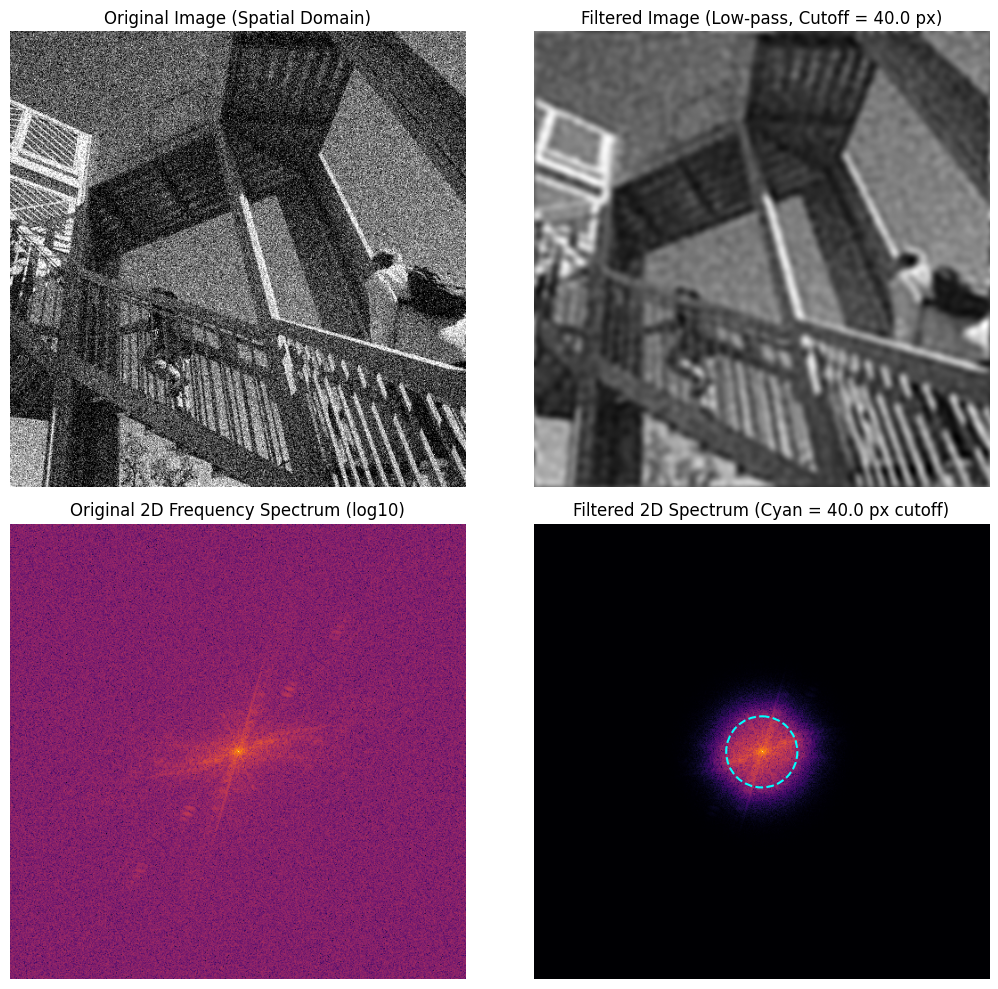

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage, datasets

# ---------------------------------------------------------
# Load (or Generate) a 2D Image Signal
# ---------------------------------------------------------
# Load a built-in grayscale test image (512x512) and normalize to [0, 1]
image = datasets.ascent().astype(float) / 255.0

# Add slight Gaussian noise (analogous to the random noise in the audio script)
noise_level = 0.18
noisy_image = image + noise_level * np.random.normal(0, 1, image.shape)
noisy_image = np.clip(noisy_image, 0, 1)

flagPass = input('Low or High pass spatial filter? [l/h]: ').strip().lower()

# ---------------------------------------------------------
# Design and Apply the 2D Spatial Filter (FFT Domain)
# ---------------------------------------------------------
def apply_spatial_filter(img, cutoff_radius, flag='l'):
    rows, cols = img.shape
    crow, ccol = rows // 2, cols // 2  # Center of the 2D frequency spectrum

    # 2D Fast Fourier Transform & shift zero-frequency component to center
    f_transform = np.fft.fft2(img)
    f_shift = np.fft.fftshift(f_transform)

    # Create a radial distance grid from the center (spatial frequencies)
    y, x = np.ogrid[:rows, :cols]
    distance = np.sqrt((x - ccol)**2 + (y - crow)**2)

    # Smooth Butterworth-style 2D frequency mask (avoids ringing artifacts)
    order = 4
    if flag in ('l', 'low'):
        print('Applying 2D low-pass spatial filtering (smoothing/blurring)...')
        mask = 1 / (1 + (distance / cutoff_radius)**(2 * order))
        filter_type = 'Low-pass'
    elif flag in ('h', 'high'):
        print('Applying 2D high-pass spatial filtering (edge detection)...')
        # Add small epsilon to avoid division by zero at the exact DC center
        mask = 1 - (1 / (1 + (distance / (cutoff_radius + 1e-6))**(2 * order)))
        filter_type = 'High-pass'
    else:
        raise ValueError("Invalid flag. Choose 'l' for low-pass or 'h' for high-pass.")

    # Apply filter mask in frequency domain and transform back to spatial domain
    f_shift_filtered = f_shift * mask
    f_ishift = np.fft.ifftshift(f_shift_filtered)
    filtered_img = np.real(np.fft.ifft2(f_ishift))

    return filtered_img, f_shift, f_shift_filtered, filter_type

# Cutoff radius in spatial frequency pixels (smaller = stronger blur / wider edges)
cutoff_freq = 40.0
filtered_image, orig_fft, filt_fft, label_text = apply_spatial_filter(
    noisy_image, cutoff_freq, flag=flagPass
)

# ---------------------------------------------------------
# Plot Spatial Domain and 2D Frequency Spectrum
# ---------------------------------------------------------
fig, axs = plt.subplots(2, 2, figsize=(11, 10))

# Top-Left: Original Image (Spatial Domain)
axs[0, 0].imshow(noisy_image, cmap='gray')
axs[0, 0].set_title('Original Image (Spatial Domain)')
axs[0, 0].axis('off')

# Top-Right: Filtered Image (Spatial Domain)
# Note: High-pass images contain negative values around edges, so we display cleanly
axs[0, 1].imshow(filtered_image, cmap='gray')
axs[0, 1].set_title(f'Filtered Image ({label_text}, Cutoff = {cutoff_freq} px)')
axs[0, 1].axis('off')

# Bottom-Left: Original 2D FFT Magnitude Spectrum (Log Scale)
orig_spectrum = np.log10(np.abs(orig_fft) + 1)
axs[1, 0].imshow(orig_spectrum, cmap='inferno')
axs[1, 0].set_title('Original 2D Frequency Spectrum (log10)')
axs[1, 0].axis('off')

# Bottom-Right: Filtered 2D FFT Magnitude Spectrum (Log Scale)
filt_spectrum = np.log10(np.abs(filt_fft) + 1)
axs[1, 1].imshow(filt_spectrum, cmap='inferno')
circle = plt.Circle((noisy_image.shape[1]//2, noisy_image.shape[0]//2),
                    cutoff_freq, color='cyan', fill=False, linestyle='--', linewidth=1.5)
axs[1, 1].add_patch(circle)
axs[1, 1].set_title(f'Filtered 2D Spectrum (Cyan = {cutoff_freq} px cutoff)')
axs[1, 1].axis('off')

plt.tight_layout()
plt.show()